<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%ED%85%8D%EC%8A%A4%ED%8A%B8%EB%B6%84%EC%84%9D%EC%8B%A4%EC%8A%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [ ]:
# 7z 설치
!apt-get install -y p7zip-full

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
p7zip-full is already the newest version (16.02+transitional.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [ ]:
# 압축 해제
!7z x /content/train.tsv.7z -o/content/


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/                   1 file, 77912192 bytes (75 MiB)

Extracting archive: /content/train.tsv.7z
--
Path = /content/train.tsv.7z
Type = 7z
Physical Size = 77912192
Headers Size = 122
Method = LZMA2:24
Solid = -
Blocks = 1

  0%      4%      9%     14%     20%     25%     30%     36%     39% - train.tsv                 41% - train.tsv                 46% - train.tsv                 51% - train.tsv                 56% - train.tsv                 62% - train.tsv                 67% - train.tsv                

In [ ]:
from sklearn.linear_model import Ridge,LogisticRegression
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer

df=pd.read_csv('/content/train.tsv',sep='\t',encoding='utf-8')
df.head(3)

,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,0,MLB Cincinnati Reds T Shirt Size XL,3,Men/Tops/T-shirts,NaN,10.0,1,No description yet
1,1,Razer BlackWidow Chroma Keyboard,3,Electronics/Computers & Tablets/Components & P...,Razer,52.0,0,This keyboard is in great condition and works ...
2,2,AVA-VIV Blouse,1,Women/Tops & Blouses/Blouse,Target,10.0,1,Adorable top with a hint of lace and a key hol...


In [ ]:
df.tail(3)

,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
1482532,1482532,21 day fix containers and eating plan,2,Sports & Outdoors/Exercise/Fitness accessories,NaN,12.0,0,"Used once or twice, still in great shape."
1482533,1482533,World markets lanterns,3,Home/Home Décor/Home Décor Accents,NaN,45.0,1,There is 2 of each one that you see! So 2 red ...
1482534,1482534,Brand new lux de ville wallet,1,Women/Women's Accessories/Wallets,NaN,22.0,0,"New with tag, red with sparkle. Firm price, no..."


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1482535 entries, 0 to 1482534
Data columns (total 8 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   train_id           1482535 non-null  int64  
 1   name               1482535 non-null  object 
 2   item_condition_id  1482535 non-null  int64  
 3   category_name      1476208 non-null  object 
 4   brand_name         849853 non-null   object 
 5   price              1482535 non-null  float64
 6   shipping           1482535 non-null  int64  
 7   item_description   1482529 non-null  object 
dtypes: float64(1), int64(3), object(4)
memory usage: 90.5+ MB


category_name,brand_name 칼럼에 null 값이 있습니다. train_id 칼럼은 인덱스로 보이니 삭제하면 될 것 같습니다.


In [ ]:
df=df.drop('train_id',axis=1)

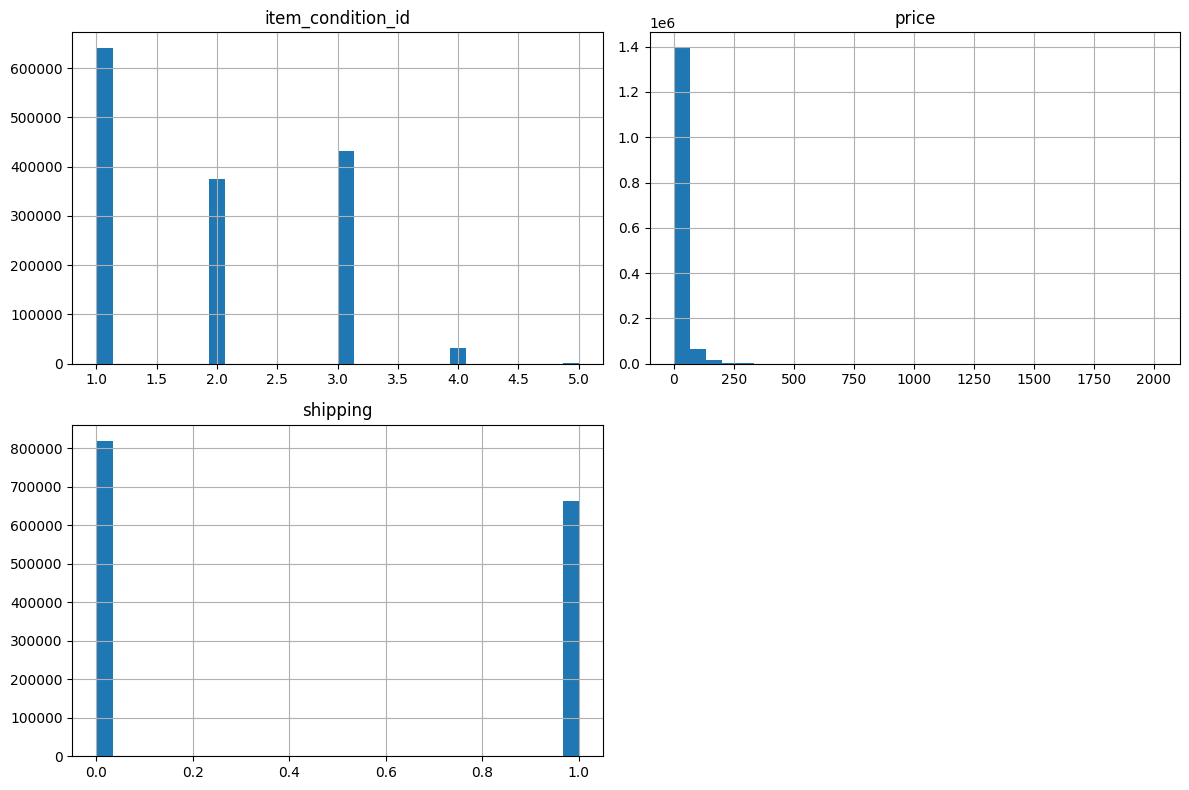

In [ ]:
numeric_df = df.select_dtypes(include='number')

numeric_df.hist(figsize=(12, 8), bins=30)

plt.tight_layout()
plt.show()

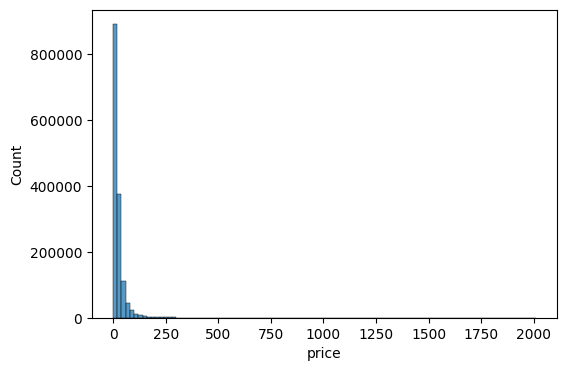

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(df['price'],bins=100)
plt.show()

price 값이 비교적 적은 가격을 가진 데이터 값에 왜곡돼 분포돼 있습니다.

price 칼럼을 로그 값으로 변환한뒤 분포도를 다시 살펴보겠습니다.

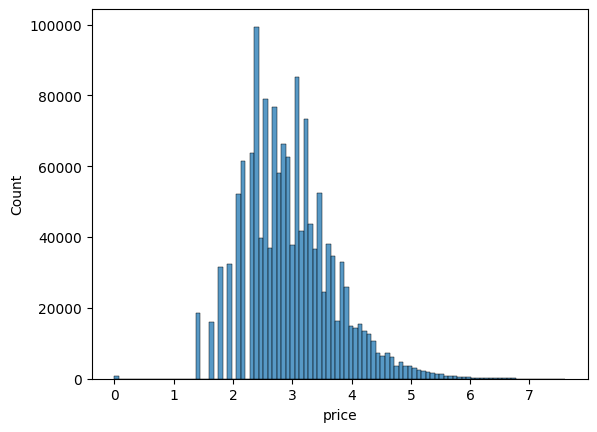

In [ ]:
price_log_df=np.log1p(df['price'])
sns.histplot(price_log_df,bins=100)
plt.show()

In [ ]:
# price 로그 변환
df['price']=np.log1p(df['price'])

In [ ]:
df.describe(include='all')

,name,item_condition_id,category_name,brand_name,price,shipping,item_description
count,1482535,1.482535e+06,1476208,849853,1.482535e+06,1.482535e+06,1482529
unique,1225273,NaN,1287,4809,NaN,NaN,1281425
top,Bundle,NaN,"Women/Athletic Apparel/Pants, Tights, Leggings",PINK,NaN,NaN,No description yet
freq,2232,NaN,60177,54088,NaN,NaN,82489
mean,NaN,1.907380e+00,NaN,NaN,2.979059e+00,4.472744e-01,NaN
std,NaN,9.031586e-01,NaN,NaN,7.492094e-01,4.972124e-01,NaN
min,NaN,1.000000e+00,NaN,NaN,0.000000e+00,0.000000e+00,NaN
25%,NaN,1.000000e+00,NaN,NaN,2.397895e+00,0.000000e+00,NaN
50%,NaN,2.000000e+00,NaN,NaN,2.890372e+00,0.000000e+00,NaN
75%,NaN,3.000000e+00,NaN,NaN,3.401197e+00,1.000000e+00,NaN


In [ ]:
df['item_condition_id'].value_counts(normalize=True)

,proportion
item_condition_id,
1,0.432063
3,0.291501
2,0.253268
4,0.021559
5,0.001608


In [ ]:
# 배송비 유무 칼럼 분포 확인
df['shipping'].value_counts(normalize=True)

,proportion
shipping,
0,0.552726
1,0.447274


item_description이 'No description yet'인 경우도 Null과 마찬가지로 의미 있는 속성값으로 사용될 수 없으므로 적절한 값으로 변경해야 합니다.

In [ ]:
boolean_cond=df['item_description']=='No description yet'
df[boolean_cond]['item_description'].count()

np.int64(82489)

category_name 칼럼은 '/'로 분리된 카테고리를 하나의 문자열로 나타내고 있습니다.

category_name 칼럼을 '/'를 기준으로 대,중,소분류를 효과적 분리하기 위해 함수를 생성하겠습니다.

In [ ]:
#apply lambda에서 호출되는 대,중,소 분할 함수 생성 대,중,소 값을 리스트로 반환
def split_cat(category_name):
  try:
    # 문자열을 '/' 기준으로 나누기
    return category_name.split('/')
  except:
    # 결측치 대체
    return['Other_Null','Other_Null','Other_Null']

# 위의 split_cat()을 apply lambda에서 호출해 대,중,소 칼럼을 df에 생성
df['cat_dae'],df['cat_jung'],df['cat_so']=zip(*df['category_name'].apply(lambda x:split_cat(x)))

# 대분류만 값의 유형과 건수를 살펴보고,중분류,소분류는 값의 유형이 많으므로 분류 개수만 추출
print(f'대분류 유형:{df['cat_dae'].value_counts()}')
print(f'중분류 개수:{df['cat_jung'].nunique()}')
print(f'소분류 개수:{df['cat_so'].nunique()}')


대분류 유형:cat_dae
Women                     664385
Beauty                    207828
Kids                      171689
Electronics               122690
Men                        93680
Home                       67871
Vintage & Collectibles     46530
Other                      45351
Handmade                   30842
Sports & Outdoors          25342
Other_Null                  6327
Name: count, dtype: int64
중분류 개수:114
소분류 개수:871


In [ ]:
# 결측치 대체
df['brand_name']=df['brand_name'].fillna(value='Other_Null')
df['category_name']=df['category_name'].fillna(value='Other_Null')
df['item_description']=df['item_description'].fillna(value='Other_Null')

# 각 컬럼별로 Null 값 건수 확인, 모두 0이 나와야 합니다.
df.isnull().sum()

,0
name,0
item_condition_id,0
category_name,0
brand_name,0
price,0
shipping,0
item_description,0
cat_dae,0
cat_jung,0
cat_so,0


### 피처 인코딩과 피처 벡터화

상품의 가격을 예측해야 하므로 회귀 모델을 기반으로 합니다.
선형 회귀 모델과 회귀 트리 모델을 모두 적용할 예정이며, 특히 **선형 회귀의 경우 원-핫 인코딩 적용이 훨씬 선호**되므로 인코딩할 피처는 모두 원-핫 인코딩을 적용하겠습니다.

피처 벡터화의 경우는 비교적 짧은 텍스트의 경우 `Count` 기반의 벡터화를, 긴 텍스트는 `TD-IDF` 기반의 벡터화를 적용하겠습니다.

In [ ]:
print(f'brand name의 유형 건수:{df['brand_name'].nunique()}')
print(f'brand name sample 5건:{df['brand_name'].value_counts()[:5]}')

brand name의 유형 건수:4810
brand name sample 5건:brand_name
Other_Null           632682
PINK                  54088
Nike                  54043
Victoria's Secret     48036
LuLaRoe               31024
Name: count, dtype: int64


brand_name의 경우 대부분 명료한 문자열로 돼 있습니다. 별도의 피처 벡터화 형태로 만들 필요 없이 인코딩 변환을 적용하면 됩니다.

brand_name의 종류가 4810건으로 원-핫 인코딩으로 변환하기에 다소 많아 보이나 본 예제의 ML 모델 구축상 큰 문제는 없습니다.

In [ ]:
print(f'brand name의 유형 건수:{df['name'].nunique()}')
print(f'brand name sample 5건:{df['name'].value_counts()[:5]}')

brand name의 유형 건수:1225273
brand name sample 5건:name
Bundle      2232
Reserved     453
Converse     445
BUNDLE       418
Dress        410
Name: count, dtype: int64


상품명은 name의 속성의 경우 종류가 매우 많습니다.

개별적으로 거의 고유한 상품명을 가지고 있습니다. Name의 속성은 유형이 매우 많고, 적은 단어 위주의 텍스트 형태로 돼 있으므로

Count 기반의 피처 벡터화 변환을 적용하겠습니다.

Item_description은 상품에 대한 간단 설명으로 데이터 세트에서 가장 긴 텍스트를 가지고 있습니다.

In [ ]:
pd.set_option('max_colwidth',200)

# item_description의 평균 문자열 크기
print(f'item_description 평균 문자열 크기:{df['item_description'].str.len().mean()}')

df['item_description'][:2]

item_description 평균 문자열 크기:145.71139703278507


,item_description
0,No description yet
1,This keyboard is in great condition and works like it came out of the box. All of the ports are tested and work perfectly. The lights are customizable via the Razer Synapse app on your PC.


평균 문자열이 145자로 비교적 크므로 해당 컬럼은 TF-IDF로 변환하겠습니다.

In [ ]:
# name과 item_description 피처벡터화
cnt_vec=CountVectorizer()
X_name=cnt_vec.fit_transform(df.name)

tfidf_descp=TfidfVectorizer(max_features=50000,ngram_range=(1,3),stop_words='english')
X_descp=tfidf_descp.fit_transform(df['item_description'])

print(f'name vectorization shape:{X_name.shape}')
print(f'item_description vectorization shape:{X_descp.shape}')

name vectorization shape:(1482535, 105757)
item_description vectorization shape:(1482535, 50000)


CountVectorizer,TfidfVectorizer가 fit_transform()을 통해 반환하는 데이터는 희소행렬 형태입니다.

사이킷런은 희소행렬 원-핫 인코딩 변환을 위해 `LabelBinarizer` 클래스를 제공합니다.

생성 시 `sparse_out=True'로 파라미터를 설정해주면 됩니다.

모든 인코딩 대상 칼럼은 `LabelBinarizer`를 이용해 희소 행렬 형태의 원-핫 인코딩으로 변환하겠습니다.

개별 칼럼으로 만들어진 희소 행렬은 사이파이 패키지 `sparse 모듈의 hstack()`을 이용해 결합하겠습니다.


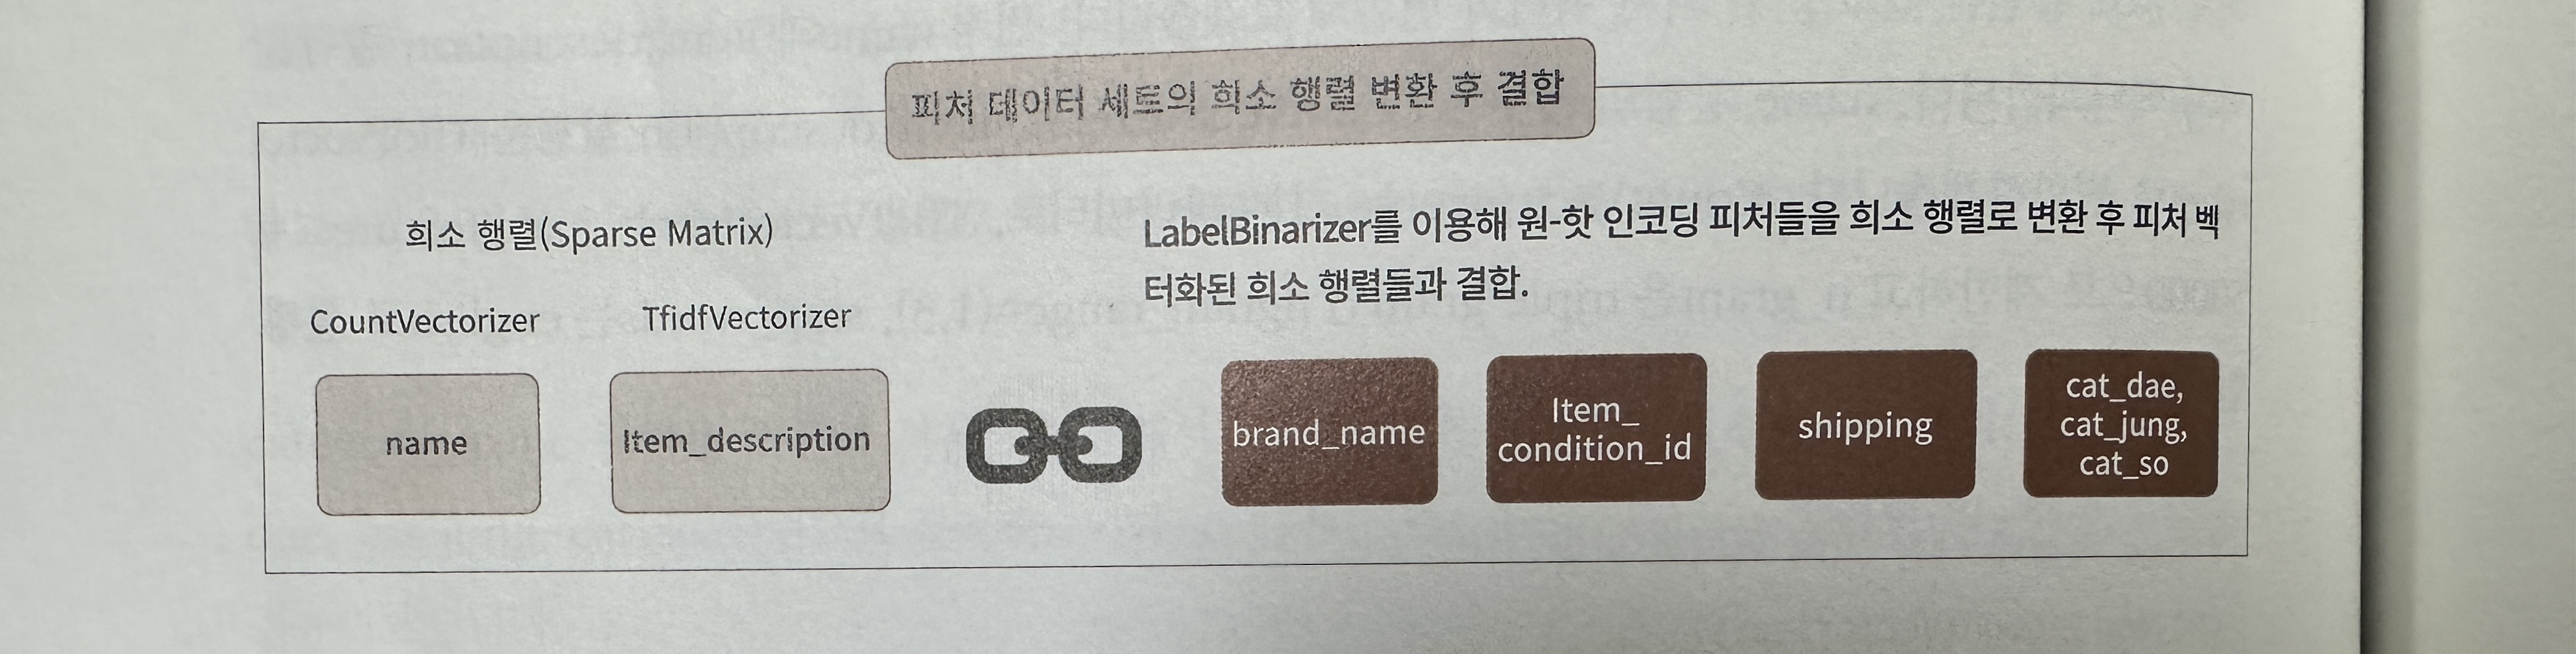

In [ ]:
# 코랩에서 10분 정도 걸림
from sklearn.preprocessing import LabelBinarizer

#brand_name,item_condition_id,shipping 각 피처들을 희소 행렬 원-핫 인코딩 변환
lb_brand_name=LabelBinarizer(sparse_output=True)
X_brand=lb_brand_name.fit_transform(df['brand_name'])
lb_item_cond_id=LabelBinarizer(sparse_output=True)
X_item_cond_id=lb_item_cond_id.fit_transform(df['item_condition_id'])
lb_shipping=LabelBinarizer(sparse_output=True)
X_shipping=lb_shipping.fit_transform(df['shipping'])

# cat_dae,cat_jung,cat_so 각 피처들을 희소 행렬 원-핫 인코딩 변환
lb_cat_dae=LabelBinarizer(sparse_output=True)
X_cat_dae=lb_cat_dae.fit_transform(df['cat_dae'])
lb_cat_jung=LabelBinarizer(sparse_output=True)
X_cat_jung=lb_cat_jung.fit_transform(df['cat_jung'])
lb_cat_so=LabelBinarizer(sparse_output=True)
X_cat_so=lb_cat_so.fit_transform(df['cat_so'])

In [ ]:
print(type(X_brand),type(X_item_cond_id),type(X_shipping))
print(f'X_brand shape:{X_brand.shape},X_item_cond_id.shape:{X_item_cond_id.shape}')
print(f'X_shipping shape:{X_shipping.shape},X_cat_dae shape:{X_cat_dae.shape}')
print(f'X_cat_jung shape:{X_cat_jung.shape},X_cat_so.shape:{X_cat_so.shape}')

<class 'scipy.sparse._csr.csr_matrix'> <class 'scipy.sparse._csr.csr_matrix'> <class 'scipy.sparse._csr.csr_matrix'>
X_brand shape:(1482535, 4810),X_item_cond_id.shape:(1482535, 5)
X_shipping shape:(1482535, 1),X_cat_dae shape:(1482535, 11)
X_cat_jung shape:(1482535, 114),X_cat_so.shape:(1482535, 871)


인코딩 변환된 데이터 세트가 CSR 형태로 변환된 csr_matrix 타입입니다.

인코딩으로 많은 칼럼들이 생겼지만, 피처 벡터화로 텍스트 형태의 문자열이 가지는 벡터 형태의 매우 많은 칼럼과 함께 결합되므로 크게 문제 될 것은 없습니다.

In [ ]:
# hstack()으로 결합
from scipy.sparse import hstack
import gc

sparse_matrix_li=(X_name,X_descp,X_brand,X_item_cond_id,X_shipping,X_cat_dae,X_cat_jung,X_cat_so)

#hstack()를 이용해 인코딩과 벡터화를 수행한 데이터 세트를 모두 결합
X_features_sparse=hstack(sparse_matrix_li).tocsr()
print(type(X_features_sparse),X_features_sparse.shape)

# 데이터 세트가 메모리를 많이 차지하므로 사용 목적이 끝났으면 바로 메모리에서 삭제
del X_features_sparse
gc.collect()

<class 'scipy.sparse._csr.csr_matrix'> (1482535, 161569)


1184

### 릿지 회귀 모델 구축 및 평가

RMSLE로 모델을 평가하는 평가 로직을 함수화하겠습니다.

RMSLE은 RMSE와 유사하나 오류 값에 로그를 취해 RMSE를 구하는 방식입니다.

낮은 가격보다 높은 가격에서 오류가 발생할 경우 오류값이 더 커지는 것을 억제하기 위해서 도입하였습니다.

In [ ]:
def rmsle(y,y_pred):
  # underflow,overflow를 막기 위해 log가 아닌 log1p로 rmsle 계산
  return np.sqrt(np.mean(np.power(np.log1p(y) - np.log1p(y_pred),2)))

def evaluate_org_price(y_test,preds):
  # 원본 데이터는 log1p로 변환되었으므로 exmpm1로 원복 필요
  preds_exmpm=np.expm1(preds)
  y_test_exmpm=np.expm1(y_test)

  #rmlse로 RMSLE 값 추출
  rmsle_result=rmsle(y_test_exmpm,preds_exmpm)
  return rmsle_result

In [ ]:
# 학습용 데이터를 생성하고 모델을 학습/예측하는 로직을 별도의 함수로 만듦
# 가비지 컬렉터(Garbage Collector) 모듈 만들기
import gc
from scipy.sparse import hstack

def model_train_predict(model,matrix_li):
  # scipy.sparse 모듈의 hstack을 이용해 희소 행렬 결합
  X=hstack(matrix_li).tocsr()

  X_train,X_test,y_train,y_test=train_test_split(X,df['price'],test_size=0.2,random_state=156)

  # 모델 학습 및 예측
  model.fit(X_train,y_train)
  preds=model.predict(X_test)

  del X,X_train,X_test,y_train
  gc.collect()

  return preds,y_test

In [ ]:
# 회귀예측 수행
linear_model=Ridge(solver='lsqr',fit_intercept=False)

sparse_matrix_li = (X_name,X_brand,X_item_cond_id,X_shipping,X_cat_dae,X_cat_jung,X_cat_so)
linear_preds,y_test=model_train_predict(model=linear_model,matrix_li=sparse_matrix_li)
print(f'Item Description을 제외했을때 rmsle 값:{evaluate_org_price(y_test,linear_preds)}')

sparse_matrix_li= (X_descp,X_name,X_brand,X_item_cond_id,
                   X_shipping,X_cat_dae,X_cat_jung,X_cat_so)
linear_preds,y_test=model_train_predict(model=linear_model,matrix_li=sparse_matrix_li)
print(f'Item Description을 포함한 rmsle 값:{evaluate_org_price(y_test,linear_preds)}')

Item Description을 제외했을때 rmsle 값:0.4983990938999374
Item Description을 포함한 rmsle 값:0.4680432471796771


Item Description을 포함했을 때 rmsle 값이 많이 감소했습니다.

### LightGBM 회귀 모델 구축과 앙상블을 이용한 최종 예측 평가

In [ ]:
from lightgbm import LGBMRegressor

sparse_matrix_li= (X_descp,X_name,X_brand,X_item_cond_id,
                   X_shipping,X_cat_dae,X_cat_jung,X_cat_so)

lgbm_model=LGBMRegressor(n_estimators=200,learning_rate=0.5,num_leaves=125,random_state=156)
lgbm_preds,y_test=model_train_predict(model=lgbm_model,matrix_li=sparse_matrix_li)
print(f'LightGBM rmsle 값:{evaluate_org_price(y_test,lgbm_preds)}')

In [ ]:
# Ridge의 예측 결과값을 서로 앙상블해 최종 예측 결과값을 도출
preds=lgbm_preds*0.45+linear_preds*0.55
print(f'LightGBM과 Ridge를 ensemble한 최종 rmsle 값:{evaluate_org_price(y_test,preds)}')

간단한 앙상블 방식으로 예측 성능 개선